# 06c — Long-context loss controls for generator attribution

This notebook follows the frozen results in notebooks 06 and 06b.

The key algebra is

\[
U(256)=L_8-L_{256}.
\]

Therefore, once \(L_8\) is already present in the baseline, adding \(U(256)\) exposes the same **linear information span** as adding \(L_{256}\). Under standardized L2-regularized logistic regression, the two parameterizations need not give numerically identical predictions because the regularization geometry changes.

This notebook asks:

1. Does attribution improve progressively as longer-context losses \(L_{32},L_{128},L_{256}\) are added beyond \(L_8\)?
2. How do \(B_{\mathrm{strong}}+L_{256}\) and \(B_{\mathrm{strong}}+U(256)\) compare?
3. Do the differences between those two parameterizations disappear under very weak regularization?

No new LM scoring is required.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, accuracy_score, f1_score

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA / "raw" / "ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS / "ghostbuster_detector_context.parquet"

assert RAW_PATH.exists(), RAW_PATH
assert CTX_PATH.exists(), CTX_PATH

raw = pd.read_parquet(RAW_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()

machine = raw[raw["generator"].isin(["gpt", "claude"])].copy()
machine["pair_id"] = machine["domain"].astype(str) + "::" + machine["group_id"].astype(str)

pc = machine.groupby("pair_id")["generator"].agg(["size", "nunique"])
valid = pc.index[(pc["size"] == 2) & (pc["nunique"] == 2)]
machine = machine[machine["pair_id"].isin(valid)].copy()

print("paired source groups:", machine["pair_id"].nunique())
print("documents:", len(machine))


paired source groups: 3000
documents: 6000


## Reconstruct the stronger transparent baseline from 06b


In [2]:
WORD_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
SENTENCE_SPLIT_RE = re.compile(r"(?<=[.!?])\s+")

FUNCTION_WORDS = {
"a","about","above","after","again","against","all","am","an","and","any","are","as","at","be","because",
"been","before","being","below","between","both","but","by","can","could","did","do","does","doing","down",
"during","each","few","for","from","further","had","has","have","having","he","her","here","hers","herself",
"him","himself","his","how","i","if","in","into","is","it","its","itself","just","me","more","most","my",
"myself","no","nor","not","now","of","off","on","once","only","or","other","our","ours","ourselves","out",
"over","own","same","she","should","so","some","such","than","that","the","their","theirs","them",
"themselves","then","there","these","they","this","those","through","to","too","under","until","up","very",
"was","we","were","what","when","where","which","while","who","whom","why","will","with","would","you",
"your","yours","yourself","yourselves"
}
PUNCT_CHARS = set(".,;:!?-—()[]{}\"'")

def lexical_entropy(tokens):
    if not tokens:
        return np.nan
    p = pd.Series(tokens).value_counts(normalize=True).to_numpy()
    return float(-(p * np.log2(p)).sum())

def style_feats(text):
    text = str(text)
    orig = WORD_RE.findall(text)
    toks = [t.lower() for t in orig]
    n = len(toks)
    if n == 0:
        return {
            "mean_sentence_words": np.nan,
            "type_token_ratio": np.nan,
            "function_word_rate": np.nan,
            "word_count": 0,
            "mean_word_length": np.nan,
            "lexical_entropy": np.nan,
            "punctuation_rate": np.nan,
            "digit_rate": np.nan,
            "uppercase_token_rate": np.nan,
        }

    sent_counts = [len(WORD_RE.findall(s)) for s in SENTENCE_SPLIT_RE.split(text.strip())]
    sent_counts = [x for x in sent_counts if x > 0]

    return {
        "mean_sentence_words": float(np.mean(sent_counts)) if sent_counts else float(n),
        "type_token_ratio": len(set(toks)) / n,
        "function_word_rate": sum(t in FUNCTION_WORDS for t in toks) / n,
        "word_count": n,
        "mean_word_length": float(np.mean([len(t) for t in toks])),
        "lexical_entropy": lexical_entropy(toks),
        "punctuation_rate": sum(ch in PUNCT_CHARS for ch in text) / max(len(text), 1),
        "digit_rate": sum(ch.isdigit() for ch in text) / max(len(text), 1),
        "uppercase_token_rate": sum(len(t) > 1 and t.isupper() for t in orig) / n,
    }

style = pd.DataFrame([
    {"row_id": r.row_id, **style_feats(r.text)}
    for r in machine[["row_id", "text"]].itertuples(index=False)
])

STYLE_STRONG = [
    "mean_sentence_words",
    "type_token_ratio",
    "function_word_rate",
    "word_count",
    "mean_word_length",
    "lexical_entropy",
    "punctuation_rate",
    "digit_rate",
    "uppercase_token_rate",
]

work = (
    machine[["row_id", "pair_id", "domain", "group_id", "generator"]]
    .merge(
        ctx[
            [
                "row_id",
                "context_loss_8",
                "context_loss_32",
                "context_loss_128",
                "context_loss_256",
                "context_u_32",
                "context_u_128",
                "context_u_256",
            ]
        ],
        on="row_id",
        how="left",
        validate="one_to_one",
    )
    .merge(style, on="row_id", how="left", validate="one_to_one")
)

needed = [
    "context_loss_8",
    "context_loss_32",
    "context_loss_128",
    "context_loss_256",
    "context_u_256",
    *STYLE_STRONG,
]
work = work.dropna(subset=needed).copy()

complete = (
    work.groupby("pair_id")["generator"]
    .agg(["size", "nunique"])
    .query("size == 2 and nunique == 2")
    .index
)
work = work[work["pair_id"].isin(complete)].copy()
work["label"] = (work["generator"] == "claude").astype(int)

print("complete pairs:", work["pair_id"].nunique())
print(work.groupby(["domain", "generator"]).size())


complete pairs: 2860
domain  generator
essay   claude       1000
        gpt          1000
reuter  claude        982
        gpt           982
wp      claude        878
        gpt           878
dtype: int64


## Feature sets

The baseline is

\[
B_{\mathrm{strong}}=(L_8,\text{nine transparent surface controls}).
\]

We then add one longer-context loss at a time:

\[
B_{\mathrm{strong}}+L_{32},
\quad
B_{\mathrm{strong}}+L_{128},
\quad
B_{\mathrm{strong}}+L_{256}.
\]

We also retain

\[
B_{\mathrm{strong}}+U(256)
\]

to compare the contrast parameterization directly with the raw long-context-loss parameterization.


In [3]:
BSTRONG = ["context_loss_8", *STYLE_STRONG]

FEATURE_SETS = {
    "Bstrong": BSTRONG,
    "Bstrong+L32": [*BSTRONG, "context_loss_32"],
    "Bstrong+L128": [*BSTRONG, "context_loss_128"],
    "Bstrong+L256": [*BSTRONG, "context_loss_256"],
    "Bstrong+U256": [*BSTRONG, "context_u_256"],
}

for k, v in FEATURE_SETS.items():
    print(k, "->", v)


Bstrong -> ['context_loss_8', 'mean_sentence_words', 'type_token_ratio', 'function_word_rate', 'word_count', 'mean_word_length', 'lexical_entropy', 'punctuation_rate', 'digit_rate', 'uppercase_token_rate']
Bstrong+L32 -> ['context_loss_8', 'mean_sentence_words', 'type_token_ratio', 'function_word_rate', 'word_count', 'mean_word_length', 'lexical_entropy', 'punctuation_rate', 'digit_rate', 'uppercase_token_rate', 'context_loss_32']
Bstrong+L128 -> ['context_loss_8', 'mean_sentence_words', 'type_token_ratio', 'function_word_rate', 'word_count', 'mean_word_length', 'lexical_entropy', 'punctuation_rate', 'digit_rate', 'uppercase_token_rate', 'context_loss_128']
Bstrong+L256 -> ['context_loss_8', 'mean_sentence_words', 'type_token_ratio', 'function_word_rate', 'word_count', 'mean_word_length', 'lexical_entropy', 'punctuation_rate', 'digit_rate', 'uppercase_token_rate', 'context_loss_256']
Bstrong+U256 -> ['context_loss_8', 'mean_sentence_words', 'type_token_ratio', 'function_word_rate', 'wo

## 20 source-held-out splits under the original L2 setup


In [4]:
def make_classifier(C=1.0):
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            solver="lbfgs",
            max_iter=4000,
            random_state=0,
            C=C,
        )),
    ])

pair_ids = np.array(sorted(work["pair_id"].unique()))
rows = []

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(pair_ids))
    cut = int(0.8 * len(pair_ids))
    train_ids = set(pair_ids[perm[:cut]])
    test_ids = set(pair_ids[perm[cut:]])

    train = work[work["pair_id"].isin(train_ids)]
    test = work[work["pair_id"].isin(test_ids)]

    for method, cols in FEATURE_SETS.items():
        model = make_classifier(C=1.0)
        model.fit(train[cols], train["label"])

        prob = model.predict_proba(test[cols])[:, 1]
        pred = (prob >= 0.5).astype(int)
        y = test["label"].to_numpy()

        rows.append({
            "seed": seed,
            "regularization": "C=1",
            "method": method,
            "auroc": roc_auc_score(y, prob),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "accuracy": accuracy_score(y, pred),
            "f1": f1_score(y, pred),
        })

results = pd.DataFrame(rows)
display(results.groupby("method")[["auroc", "balanced_accuracy", "f1"]].mean().sort_values("auroc", ascending=False))


,auroc,balanced_accuracy,f1
method,,,
Bstrong+U256,0.890216,0.805114,0.808678
Bstrong+L256,0.890215,0.805114,0.808630
Bstrong+L128,0.889673,0.808872,0.812144
Bstrong+L32,0.882699,0.798776,0.802922
Bstrong,0.875544,0.789948,0.794600


In [5]:
def delta_summary(df, a, b, metric="auroc"):
    w = df.pivot(index="seed", columns="method", values=metric)
    vals = (w[a] - w[b]).to_numpy()
    return {
        "comparison": f"{a} vs {b}",
        "metric": metric,
        "mean_delta": vals.mean(),
        "median_delta": np.median(vals),
        "q25": np.quantile(vals, 0.25),
        "q75": np.quantile(vals, 0.75),
        "min": vals.min(),
        "max": vals.max(),
        "positive": int((vals > 0).sum()),
        "n": len(vals),
    }

comparisons = []
for a, b in [
    ("Bstrong+L32", "Bstrong"),
    ("Bstrong+L128", "Bstrong"),
    ("Bstrong+L256", "Bstrong"),
    ("Bstrong+U256", "Bstrong"),
    ("Bstrong+U256", "Bstrong+L256"),
]:
    for metric in ["auroc", "balanced_accuracy", "f1"]:
        comparisons.append(delta_summary(results, a, b, metric))

summary = pd.DataFrame(comparisons)
display(summary)

results.to_csv(RESULTS / "context_loss_scale_controls_source_splits.csv", index=False)
summary.to_csv(RESULTS / "context_loss_scale_controls_summary.csv", index=False)


,comparison,metric,mean_delta,median_delta,q25,q75,min,max,positive,n
0,Bstrong+L32 vs Bstrong,auroc,7.154690e-03,0.007108,0.006352,0.007754,0.002589,0.012048,20,20
1,Bstrong+L32 vs Bstrong,balanced_accuracy,8.828671e-03,0.008741,0.005245,0.013330,-0.001748,0.019231,18,20
2,Bstrong+L32 vs Bstrong,f1,8.322066e-03,0.008207,0.004630,0.013002,-0.001422,0.018836,18,20
3,Bstrong+L128 vs Bstrong,auroc,1.412829e-02,0.014842,0.010087,0.016440,0.007173,0.022250,20,20
4,Bstrong+L128 vs Bstrong,balanced_accuracy,1.892483e-02,0.018357,0.015516,0.023164,0.000874,0.033217,20,20
5,Bstrong+L128 vs Bstrong,f1,1.754397e-02,0.016650,0.014313,0.021244,0.000340,0.031074,20,20
6,Bstrong+L256 vs Bstrong,auroc,1.467049e-02,0.014351,0.011915,0.016557,0.006385,0.022321,20,20
7,Bstrong+L256 vs Bstrong,balanced_accuracy,1.516608e-02,0.014423,0.009615,0.021853,0.001748,0.027972,20,20
8,Bstrong+L256 vs Bstrong,f1,1.403087e-02,0.013251,0.008942,0.020004,0.002084,0.025029,20,20
9,Bstrong+U256 vs Bstrong,auroc,1.467171e-02,0.014360,0.011910,0.016540,0.006415,0.022336,20,20


## Weak-regularization diagnostic

Because \((L_8,U_{256})\) and \((L_8,L_{256})\) span the same linear information space, their predictions should converge as regularization becomes negligible.

We rerun only the relevant feature sets with very weak L2 regularization:

\[
C=10^6.
\]

This is a diagnostic, not the headline classifier.


In [6]:
weak_rows = []

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(pair_ids))
    cut = int(0.8 * len(pair_ids))
    train_ids = set(pair_ids[perm[:cut]])
    test_ids = set(pair_ids[perm[cut:]])

    train = work[work["pair_id"].isin(train_ids)]
    test = work[work["pair_id"].isin(test_ids)]

    for method in ["Bstrong", "Bstrong+L256", "Bstrong+U256"]:
        cols = FEATURE_SETS[method]
        model = make_classifier(C=1e6)
        model.fit(train[cols], train["label"])

        prob = model.predict_proba(test[cols])[:, 1]
        pred = (prob >= 0.5).astype(int)
        y = test["label"].to_numpy()

        weak_rows.append({
            "seed": seed,
            "regularization": "C=1e6",
            "method": method,
            "auroc": roc_auc_score(y, prob),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "accuracy": accuracy_score(y, pred),
            "f1": f1_score(y, pred),
        })

weak = pd.DataFrame(weak_rows)

display(
    weak.groupby("method")[["auroc", "balanced_accuracy", "f1"]]
    .mean()
    .sort_values("auroc", ascending=False)
)

weak_summary = []
for a, b in [
    ("Bstrong+L256", "Bstrong"),
    ("Bstrong+U256", "Bstrong"),
    ("Bstrong+U256", "Bstrong+L256"),
]:
    for metric in ["auroc", "balanced_accuracy", "f1"]:
        weak_summary.append(delta_summary(weak, a, b, metric))

weak_summary = pd.DataFrame(weak_summary)
display(weak_summary)

weak.to_csv(RESULTS / "context_loss_scale_controls_weakreg_splits.csv", index=False)
weak_summary.to_csv(RESULTS / "context_loss_scale_controls_weakreg_summary.csv", index=False)


,auroc,balanced_accuracy,f1
method,,,
Bstrong+L256,0.890276,0.805507,0.809022
Bstrong+U256,0.890275,0.805638,0.809159
Bstrong,0.875682,0.789773,0.794465


,comparison,metric,mean_delta,median_delta,q25,q75,min,max,positive,n
0,Bstrong+L256 vs Bstrong,auroc,1.459301e-02,0.014293,0.011864,0.016511,0.006400,0.022416,20,20
1,Bstrong+L256 vs Bstrong,balanced_accuracy,1.573427e-02,0.015734,0.011582,0.021198,0.001748,0.028846,20,20
2,Bstrong+L256 vs Bstrong,f1,1.455748e-02,0.015244,0.011262,0.019372,0.002435,0.026845,20,20
3,Bstrong+U256 vs Bstrong,auroc,1.459240e-02,0.014301,0.011852,0.016521,0.006409,0.022412,20,20
4,Bstrong+U256 vs Bstrong,balanced_accuracy,1.586538e-02,0.015734,0.011582,0.022072,0.000874,0.028846,20,20
5,Bstrong+U256 vs Bstrong,f1,1.469392e-02,0.015396,0.011262,0.020878,0.001751,0.026845,20,20
6,Bstrong+U256 vs Bstrong+L256,auroc,-6.112768e-07,-0.000002,-0.000007,0.000009,-0.000034,0.000031,9,20
7,Bstrong+U256 vs Bstrong+L256,balanced_accuracy,1.311189e-04,0.000000,0.000000,0.000000,-0.000874,0.001748,3,20
8,Bstrong+U256 vs Bstrong+L256,f1,1.364489e-04,0.000000,0.000000,0.000000,-0.000684,0.002009,3,20


## Held-out-domain transfer for \(L_k\) controls

This mirrors 06b and asks whether the longer-context-loss gains persist when the target domain is entirely unseen.


In [7]:
DOMAIN_LABELS = {"essay": "Essay", "reuter": "Reuters", "wp": "Wikipedia"}

transfer_rows = []

for heldout in ["essay", "reuter", "wp"]:
    train = work[work["domain"] != heldout]
    test = work[work["domain"] == heldout]

    for method, cols in FEATURE_SETS.items():
        model = make_classifier(C=1.0)
        model.fit(train[cols], train["label"])

        prob = model.predict_proba(test[cols])[:, 1]
        pred = (prob >= 0.5).astype(int)
        y = test["label"].to_numpy()

        transfer_rows.append({
            "heldout_domain": heldout,
            "heldout_domain_label": DOMAIN_LABELS[heldout],
            "method": method,
            "auroc": roc_auc_score(y, prob),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "accuracy": accuracy_score(y, pred),
            "f1": f1_score(y, pred),
        })

transfer = pd.DataFrame(transfer_rows)
transfer.to_csv(RESULTS / "context_loss_scale_controls_cross_domain.csv", index=False)

display(
    transfer.pivot(
        index="heldout_domain_label",
        columns="method",
        values="auroc",
    )
)


method,Bstrong,Bstrong+L128,Bstrong+L256,Bstrong+L32,Bstrong+U256
heldout_domain_label,,,,,
Essay,0.866216,0.883268,0.883335,0.874037,0.883273
Reuters,0.854669,0.870256,0.871647,0.862690,0.871687
Wikipedia,0.747694,0.777289,0.774063,0.766626,0.774058


In [8]:
transfer_deltas = []

for heldout in ["essay", "reuter", "wp"]:
    sub = transfer[transfer["heldout_domain"] == heldout].set_index("method")
    for a, b in [
        ("Bstrong+L32", "Bstrong"),
        ("Bstrong+L128", "Bstrong"),
        ("Bstrong+L256", "Bstrong"),
        ("Bstrong+U256", "Bstrong"),
    ]:
        transfer_deltas.append({
            "heldout_domain": heldout,
            "heldout_domain_label": DOMAIN_LABELS[heldout],
            "comparison": f"{a} vs {b}",
            "delta_auroc": sub.loc[a, "auroc"] - sub.loc[b, "auroc"],
            "delta_balanced_accuracy": sub.loc[a, "balanced_accuracy"] - sub.loc[b, "balanced_accuracy"],
            "delta_f1": sub.loc[a, "f1"] - sub.loc[b, "f1"],
        })

transfer_deltas = pd.DataFrame(transfer_deltas)
transfer_deltas.to_csv(RESULTS / "context_loss_scale_controls_cross_domain_deltas.csv", index=False)

display(
    transfer_deltas.pivot(
        index="heldout_domain_label",
        columns="comparison",
        values="delta_auroc",
    )
)


comparison,Bstrong+L128 vs Bstrong,Bstrong+L256 vs Bstrong,Bstrong+L32 vs Bstrong,Bstrong+U256 vs Bstrong
heldout_domain_label,,,,
Essay,0.017052,0.017119,0.007821,0.017057
Reuters,0.015587,0.016978,0.008021,0.017018
Wikipedia,0.029596,0.026370,0.018933,0.026365


## Headline diagnostic figure

The first panel shows mean source-held-out AUROC by feature set.

The second panel shows the mean AUROC gain over \(B_{\mathrm{strong}}\) as the added scorer window increases from 32 to 256 tokens.


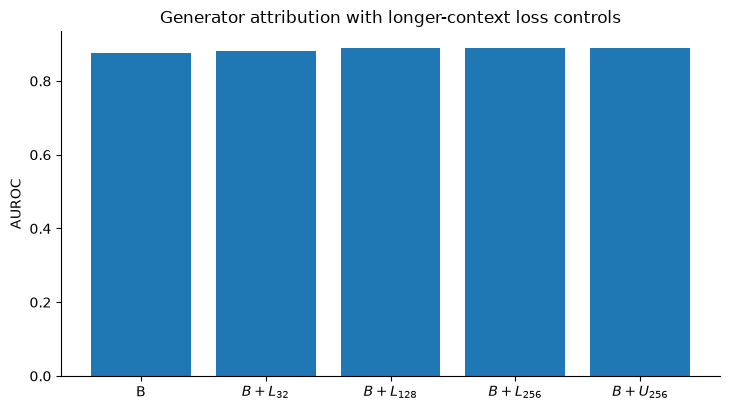

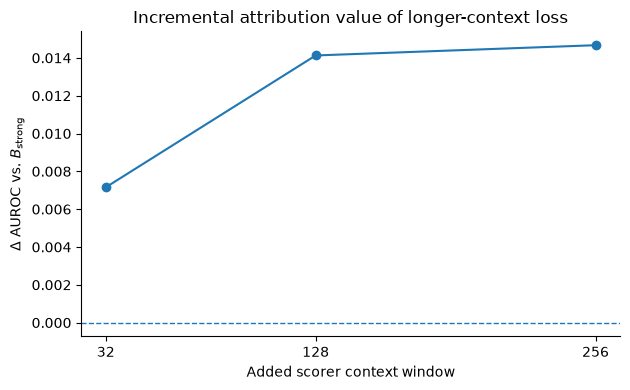

In [9]:
means = results.groupby("method")["auroc"].mean()

order = ["Bstrong", "Bstrong+L32", "Bstrong+L128", "Bstrong+L256", "Bstrong+U256"]

fig, ax = plt.subplots(figsize=(7.4, 4.2))
x = np.arange(len(order))
ax.bar(x, [means[m] for m in order])
ax.set_xticks(x)
ax.set_xticklabels(["B", r"$B+L_{32}$", r"$B+L_{128}$", r"$B+L_{256}$", r"$B+U_{256}$"])
ax.set_ylabel("AUROC")
ax.set_title("Generator attribution with longer-context loss controls")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "context_loss_scale_controls_auroc.pdf", bbox_inches="tight")
fig.savefig(FIGURES / "context_loss_scale_controls_auroc.png", dpi=200, bbox_inches="tight")
plt.show()

gains = [
    means["Bstrong+L32"] - means["Bstrong"],
    means["Bstrong+L128"] - means["Bstrong"],
    means["Bstrong+L256"] - means["Bstrong"],
]

fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot([32, 128, 256], gains, marker="o")
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xticks([32, 128, 256])
ax.set_xlabel("Added scorer context window")
ax.set_ylabel(r"$\Delta$ AUROC vs. $B_{\mathrm{strong}}$")
ax.set_title("Incremental attribution value of longer-context loss")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "context_loss_scale_gain_curve.pdf", bbox_inches="tight")
fig.savefig(FIGURES / "context_loss_scale_gain_curve.png", dpi=200, bbox_inches="tight")
plt.show()


## Interpretation

There are three particularly informative outcomes.

### A. Increasing context length gives increasing attribution value

If

\[
\Delta(B+L_{32}) < \Delta(B+L_{128}) < \Delta(B+L_{256}),
\]

then the additional generator information grows with scorer context range. This is consistent with the idea that longer-range predictive structure carries source information.

### B. \(B+U(256)\) and \(B+L_{256}\) become equivalent under weak regularization

That is expected from the exact linear relation

\[
U(256)=L_8-L_{256}.
\]

In that case, the correct claim is not that the subtraction itself creates new information. The result is that **long-context predictive loss adds information beyond short-context loss and surface controls**.

### C. The gain transfers across held-out domains

That weakens a simple within-domain style-correlation explanation.

None of these results alone proves that long-context loss uniquely identifies generation-time dependency structure. They characterize the predictive content of the measurement more precisely before the multi-scorer experiment.


In [10]:
def fs(x):
    return f"{x:+.5f}"

print("C=1 SOURCE-HELD-OUT AUROC GAINS")
for method in ["Bstrong+L32", "Bstrong+L128", "Bstrong+L256", "Bstrong+U256"]:
    row = summary[
        (summary["comparison"] == f"{method} vs Bstrong")
        & (summary["metric"] == "auroc")
    ].iloc[0]
    print(
        method,
        "| mean", fs(row.mean_delta),
        "| median", fs(row.median_delta),
        "| IQR", f"[{fs(row.q25)}, {fs(row.q75)}]",
        "| positive", f"{int(row.positive)}/{int(row.n)}",
    )

print("\nC=1 PARAMETERIZATION DIFFERENCE")
row = summary[
    (summary["comparison"] == "Bstrong+U256 vs Bstrong+L256")
    & (summary["metric"] == "auroc")
].iloc[0]
print(
    "U256 vs L256",
    "| mean", fs(row.mean_delta),
    "| median", fs(row.median_delta),
    "| positive", f"{int(row.positive)}/{int(row.n)}",
)

print("\nC=1e6 PARAMETERIZATION DIFFERENCE")
row = weak_summary[
    (weak_summary["comparison"] == "Bstrong+U256 vs Bstrong+L256")
    & (weak_summary["metric"] == "auroc")
].iloc[0]
print(
    "U256 vs L256",
    "| mean", fs(row.mean_delta),
    "| median", fs(row.median_delta),
    "| positive", f"{int(row.positive)}/{int(row.n)}",
)


C=1 SOURCE-HELD-OUT AUROC GAINS
Bstrong+L32 | mean +0.00715 | median +0.00711 | IQR [+0.00635, +0.00775] | positive 20/20
Bstrong+L128 | mean +0.01413 | median +0.01484 | IQR [+0.01009, +0.01644] | positive 20/20
Bstrong+L256 | mean +0.01467 | median +0.01435 | IQR [+0.01192, +0.01656] | positive 20/20
Bstrong+U256 | mean +0.01467 | median +0.01436 | IQR [+0.01191, +0.01654] | positive 20/20

C=1 PARAMETERIZATION DIFFERENCE
U256 vs L256 | mean +0.00000 | median +0.00000 | positive 12/20

C=1e6 PARAMETERIZATION DIFFERENCE
U256 vs L256 | mean -0.00000 | median -0.00000 | positive 9/20
